# Simple analysis of historic returns on portfolio including BTCUSDC perp comparison

- In this notebook we analyze historical returns on portfolios with different levels of "risk", trying to replicate the results that Bodie, Kane and Marcus (2024) on its book "Investments" show for this specific section

- Data for T-bills and T-bonds are stracterd from the Kenneth French data library and Damodaran historical return asset

- We also implement the same analysis fro the BTCUSDC perp data, although with limitations regarding to time (the future only has around 2 - 3 years of data)

# 1. Libs

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas_datareader.data as web
import seaborn as sns

from CAPM_model import (
    plot_return_distribution,
    value_at_risk,
    lower_partial_standard_deviation,
    sortino_ratio,
    negative_three_sigma_frequency,
)
from utils import download_klines, SYMBOL, BASE_URL

# 2. Get data

In [34]:
ff = web.DataReader(
    "F-F_Research_Data_Factors",
    "famafrench",
    start="1926-07-01",
)
# This data already contains retruns not prices!
annual = ff[1].copy()
annual = annual / 100  # we want decimals
# we are recovering the us market return just by  adding the risk free rate to the market risk free rate returns!
annual["US_Market"] = annual["Mkt-RF"] + annual["RF"]

annual["T_Bills"] = annual["RF"]
returns = annual[["US_Market", "T_Bills"]]
print(returns.head())
print(returns.tail())

# now getting the monthly returns

monthly = ff[0].copy() / 100
excess_returns = monthly["Mkt-RF"]
print(excess_returns.head())
rolling_volatility = excess_returns.rolling(window=12).std(ddof=1)

      US_Market  T_Bills
Date                    
1927     0.3256   0.0312
1928     0.3912   0.0356
1929    -0.1483   0.0475
1930    -0.2873   0.0241
1931    -0.4377   0.0107
      US_Market  T_Bills
Date                    
2021     0.2391   0.0004
2022    -0.1990   0.0142
2023     0.2670   0.0495
2024     0.2502   0.0526
2025     0.1755   0.0425
Date
1926-07    0.0289
1926-08    0.0264
1926-09    0.0038
1926-10   -0.0327
1926-11    0.0254
Freq: M, Name: Mkt-RF, dtype: float64


In [35]:
# getting BTCUSDC perp data

btcusdcp = download_klines(SYMBOL, "2024-12-31", "2026-11-01")

display(btcusdcp.head())

,date,close
0,2024-12-31 00:00:00+00:00,93384.0
1,2025-01-01 00:00:00+00:00,94402.5
2,2025-01-02 00:00:00+00:00,96907.9
3,2025-01-03 00:00:00+00:00,98139.7
4,2025-01-04 00:00:00+00:00,98195.4


# 3. Following book analysis

## 3.1. Analyzing direct US eturns and comparing with normal distributiosn with their parameters

In [36]:
# we estimate the riskfree rate from T-bills
risk_free_rate = np.mean(returns["T_Bills"].dropna())
risk_free_rate

np.float64(0.03330808080808081)

,Mean,Standard deviation,Risk Premium,Max,Min
US_Market,0.121935,0.198368,0.088627,0.5679,-0.4377


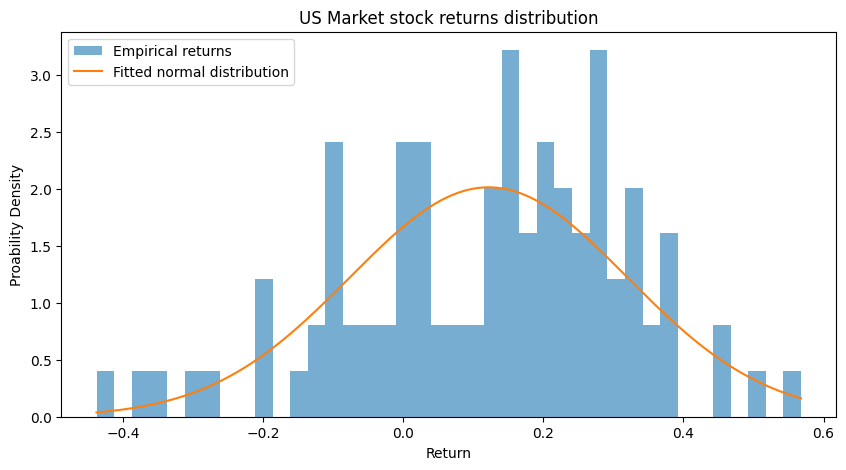

In [37]:
mean = np.mean(returns["US_Market"].dropna())
std = np.std(returns["US_Market"].dropna(), ddof=1)
risk_premium = mean - risk_free_rate

stats = {
    "Mean": mean,
    "Standard deviation": std,
    "Risk Premium": risk_premium,
    "Max": returns["US_Market"].max(),
    "Min": returns["US_Market"].min(),
}


df = pd.DataFrame(stats, index=["US_Market"])
display(df)

plot_return_distribution(
    returns["US_Market"].dropna(), "US Market stock returns distribution", compare=True
)

,Mean,Standard deviation,Risk Premium,Max,Min
T_Bills,0.033308,0.030579,0.0,0.1471,-0.0002


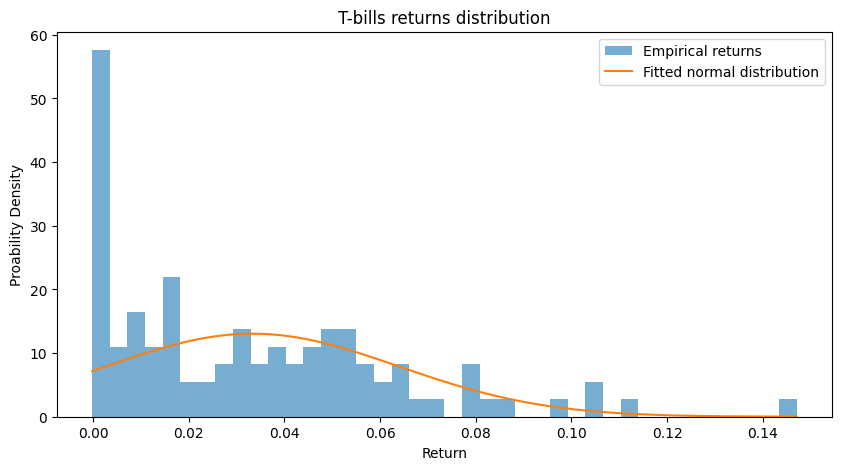

In [38]:
mean = np.mean(returns["T_Bills"].dropna())
std = np.std(returns["T_Bills"].dropna(), ddof=1)
risk_premium = mean - risk_free_rate

stats = {
    "Mean": mean,
    "Standard deviation": std,
    "Risk Premium": risk_premium,
    "Max": returns["T_Bills"].max(),
    "Min": returns["T_Bills"].min(),
}


df = pd.DataFrame(stats, index=["T_Bills"])
display(df)

plot_return_distribution(
    returns["T_Bills"].dropna(), "T-bills returns distribution", compare=True
)

## 3.2 Now lets use log returns instead

In [39]:
returns["log_US_Market"] = np.log1p(returns["US_Market"].dropna())
returns["log_T_Bills"] = np.log1p(returns["T_Bills"].dropna())
returns.head()

,US_Market,T_Bills,log_US_Market,log_T_Bills
Date,,,,
1927,0.3256,0.0312,0.281865,0.030723
1928,0.3912,0.0356,0.330167,0.034981
1929,-0.1483,0.0475,-0.160521,0.046406
1930,-0.2873,0.0241,-0.338695,0.023814
1931,-0.4377,0.0107,-0.575720,0.010643


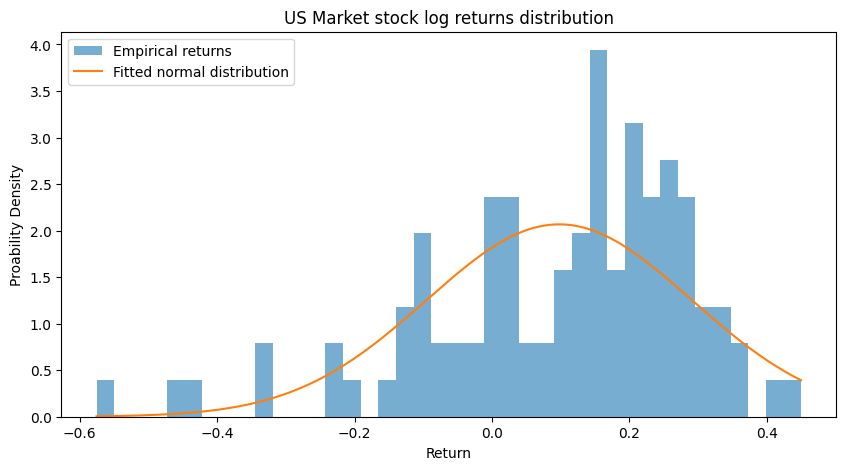

In [40]:
plot_return_distribution(
    returns["log_US_Market"].dropna(),
    "US Market stock log returns distribution",
    compare=True,
)

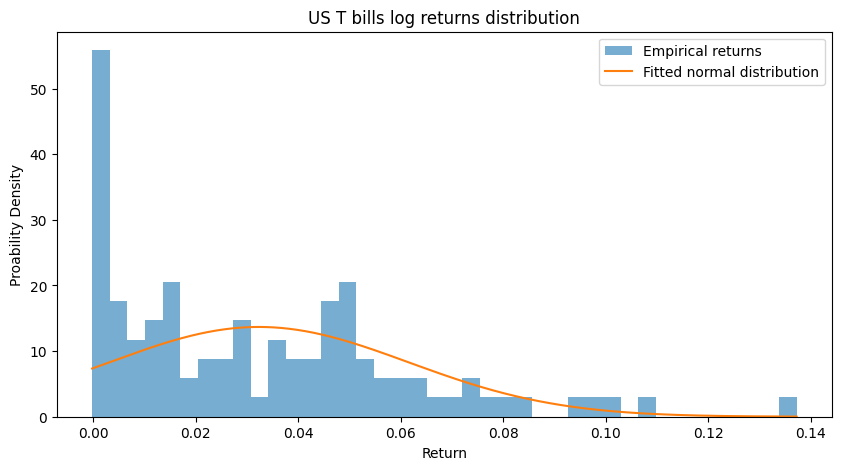

In [41]:
plot_return_distribution(
    returns["log_T_Bills"].dropna(), "US T bills log returns distribution", compare=True
)

## 3.3 Analyzing monthly excess return on the market index portolio


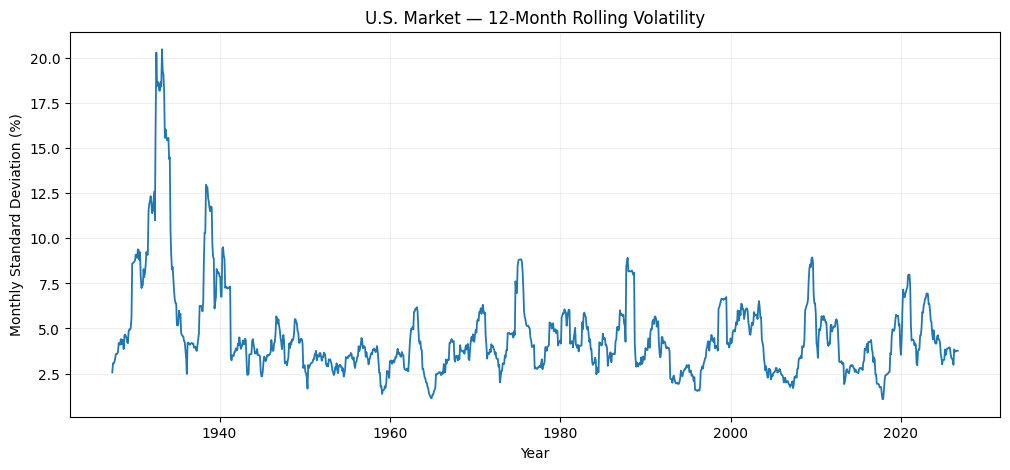

In [42]:
# 12-month rolling standard deviation of monthly excess returns
rolling_monthly_volatility = excess_returns.rolling(window=12).std(ddof=1)

# Convert monthly volatility to annualized volatility
rolling_annualized_volatility = rolling_monthly_volatility * np.sqrt(12)

rolling_volatility_pct = rolling_volatility * 100

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    rolling_volatility_pct.index.to_timestamp(),
    rolling_volatility_pct,
    linewidth=1.3,
)

ax.set(
    title="U.S. Market — 12-Month Rolling Volatility",
    xlabel="Year",
    ylabel="Monthly Standard Deviation (%)",
)

ax.grid(alpha=0.2)
plt.show()

## 3.4 Frequency distribution of monthly excess returns on the market index versus modeled frequency from a normal distribution with matched mean and standard deviation

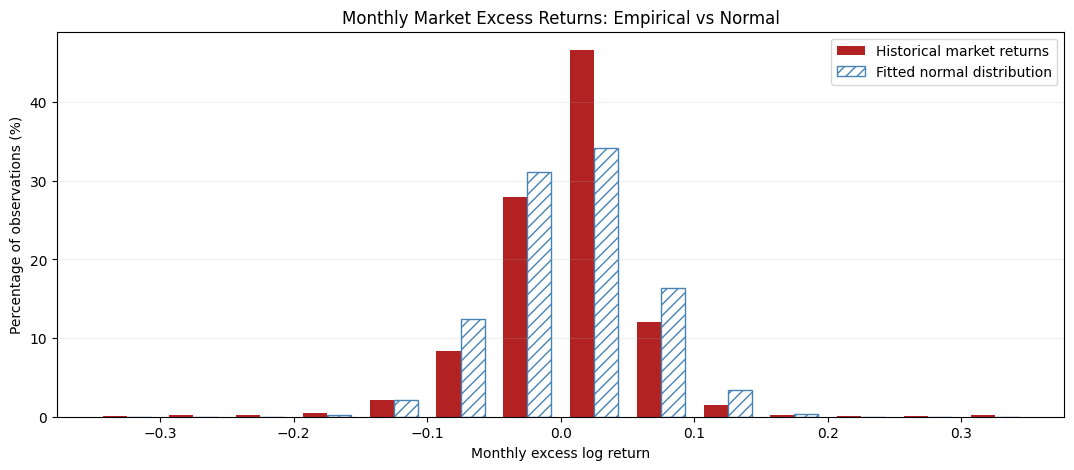

In [46]:
from scipy.stats import norm

market_simple = monthly["Mkt-RF"] + monthly["RF"]
rf_simple = monthly["RF"]

# Continuously compounded excess return
market_log_excess = (np.log1p(market_simple) - np.log1p(rf_simple)).dropna()

# Estimate normal distribution parameters
mu = market_log_excess.mean()
sigma = market_log_excess.std(ddof=1)
edges = np.arange(-0.35, 0.40, 0.05)

# Empirical frequency per bin
counts, _ = np.histogram(market_log_excess, bins=edges)
empirical_pct = counts / len(market_log_excess) * 100

# Theoretical normal probability per bin
normal_pct = (
    norm.cdf(edges[1:], loc=mu, scale=sigma) - norm.cdf(edges[:-1], loc=mu, scale=sigma)
) * 100

# Plot paired bars
centers = (edges[:-1] + edges[1:]) / 2
bar_width = 0.018

fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    centers - bar_width / 2,
    empirical_pct,
    width=bar_width,
    color="firebrick",
    label="Historical market returns",
)

ax.bar(
    centers + bar_width / 2,
    normal_pct,
    width=bar_width,
    facecolor="white",
    edgecolor="steelblue",
    hatch="///",
    label="Fitted normal distribution",
)

ax.set(
    title="Monthly Market Excess Returns: Empirical vs Normal",
    xlabel="Monthly excess log return",
    ylabel="Percentage of observations (%)",
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.show()

# 4. Implementing time series analysis for BTCUSC

In [47]:
btcusdcp["log_returns"] = np.log(btcusdcp["close"] / btcusdcp["close"].shift(1))
btcusdcp["returns"] = (btcusdcp["close"] / btcusdcp["close"].shift(1)) - 1
btcusdcp = btcusdcp.dropna()
N = len(btcusdcp["log_returns"].dropna())

print(N)
display(btcusdcp.tail())

669


,date,close,log_returns,returns
665,2026-10-27 00:00:00+00:00,80784.4,0.009617,0.009664
666,2026-10-28 00:00:00+00:00,81233.9,0.005549,0.005564
667,2026-10-29 00:00:00+00:00,77816.4,-0.042980,-0.042070
668,2026-10-30 00:00:00+00:00,77204.1,-0.007900,-0.007869
669,2026-10-31 00:00:00+00:00,77432.0,0.002948,0.002952


In [51]:
# we need to convert annual risk free rate into a daily
daily_risk_free_rate = (1 + risk_free_rate) ** (1 / 365) - 1
daily_risk_free_rate

np.float64(8.977220626071869e-05)

,mean,geometric_mean,std,skewness,kurtosis,sharpe_ratio
0,-0.00028,-0.00028,0.022601,-0.116965,5.055309,-0.016361


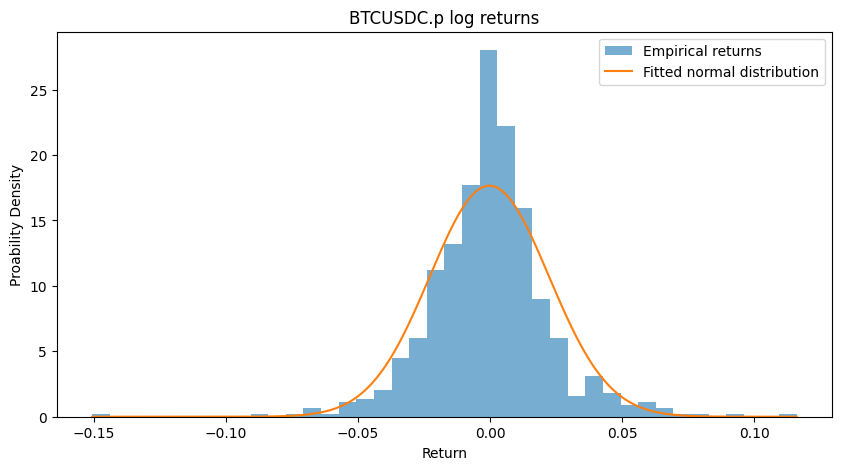

In [52]:
report = {}

report["mean"] = btcusdcp["log_returns"].mean()
report["geometric_mean"] = np.exp(report["mean"]) - 1
report["std"] = np.std(btcusdcp["log_returns"], ddof=1)
report["skewness"] = btcusdcp["log_returns"].skew()
report["kurtosis"] = btcusdcp["log_returns"].kurtosis()
report["sharpe_ratio"] = (report["mean"] - daily_risk_free_rate) / report["std"]
display(pd.DataFrame([report]))
plot_return_distribution(btcusdcp["log_returns"], "BTCUSDC.p log returns", compare=True)

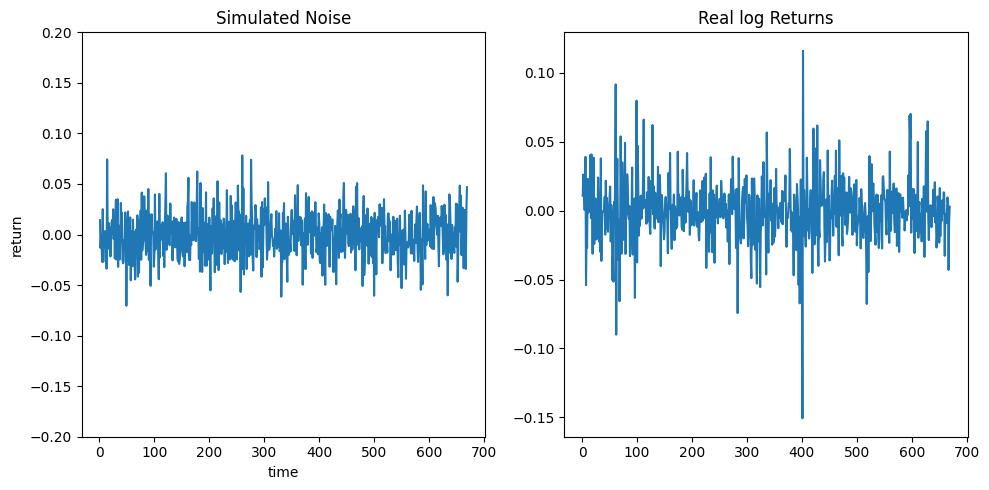

In [30]:
# simulating a random walk with the btc properties

noise = np.random.normal(loc=report["mean"], scale=report["std"], size=len(btcusdcp))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Primer gráfico (izquierda)
ax1.plot(btcusdcp.index, noise)
ax1.set_ylim(-0.2, 0.2)
ax1.set_xlabel("time")
ax1.set_ylabel("return")
ax1.set_title("Simulated Noise")


ax2.plot(btcusdcp.index, btcusdcp["log_returns"])
ax2.set_title("Real log Returns")

plt.tight_layout()
plt.show()